# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [392]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

NAME_CLIENTS = "clients.csv"
NAME_TXN = "transactions.csv"
DATA_PATH = Path("..")/ "data" / "raw"
RAW_CLIENTS = DATA_PATH / NAME_CLIENTS
RAW_TXN = DATA_PATH / NAME_TXN


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [393]:
df_naiveCLIENTS = pd.read_csv(RAW_CLIENTS)
print('------1------')
df_naiveCLIENTS.info()
print(df_naiveCLIENTS.dtypes.value_counts())
df_naiveCLIENTS.head(15)

------1------
<class 'pandas.DataFrame'>
RangeIndex: 5693 entries, 0 to 5692
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5693 non-null   str    
 1   birth_date          5693 non-null   str    
 2   gender              5693 non-null   str    
 3   city                5693 non-null   str    
 4   segment             5693 non-null   str    
 5   loyalty_tier        5693 non-null   str    
 6   card_type           5693 non-null   str    
 7   registration_date   5693 non-null   str    
 8   card_open_date      5693 non-null   str    
 9   income_source       5693 non-null   str    
 10  monthly_income      5140 non-null   float64
 11  has_mobile_app      5693 non-null   str    
 12  app_last_login      3527 non-null   str    
 13  satisfaction_score  2324 non-null   float64
 14  branch_code         5693 non-null   int64  
 15  marketing_opt_in    5693 non-null   str    
dtypes: 

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001415,1968-12-11,М,СПб,Массовый,Базовый,Дебетовая,16.02.2015,10.06.2019,Не указан,NaN,Нет,NaN,NaN,119,Да
1,C005054,1969-11-01,М,Санкт-Петербург,Массовый,Базовый,Кредитная,22.01.2014,27.07.2016,Не указан,69900.0,Нет,NaN,NaN,707,Нет
2,C005780,1958-01-17,М,г. Москва,Массовый,Серебро,Дебетовая,30.06.2015,18.12.2017,Не указан,NaN,Да,2024-01,NaN,180,Да
3,C003736,1983-04-14,М,Казань,Массовый,Базовый,Дебетовая,18.11.2017,01.01.2022,Не указан,67400.0,Да,2024-07,NaN,681,Да
4,C004260,1972-01-05,М,Новосибирск,Private,Платина,Дебетовая,02.03.2015,03.03.2020,Не указан,481900.0,Да,2025-06,NaN,541,Да
5,C001207,1974-09-09,М,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,26.12.2018,21.06.2022,Не указан,NaN,Да,2024-07,NaN,782,Да
6,C002874,1956-08-24,М,СПб,Зарплатный,Базовый,Дебетовая,17.09.2022,22.04.2025,Зарплата в нашем банке,79400.0,Да,2024-10,NaN,729,Нет
7,C002842,1978-04-05,Ж,Екатеринбург,Премиальный,Серебро,Премиальная,17.03.2022,16.10.2022,Не указан,NaN,Да,2025-02,NaN,898,Нет
8,C001447,1972-07-11,М,Новосибирск,Премиальный,Серебро,Кредитная,02.05.2011,13.07.2016,Не указан,184700.0,Да,2024-12,NaN,874,Да
9,C000948,1963-01-17,Ж,Санкт Петербург,Зарплатный,Серебро,Дебетовая,12.08.2016,13.11.2021,Зарплата в нашем банке,67700.0,Да,2024-07,NaN,563,Нет


In [394]:
df_naiveTXN = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")
print('------2------')
df_naiveTXN.info()
print(df_naiveTXN.dtypes.value_counts())
df_naiveTXN.head(15)

------2------
<class 'pandas.DataFrame'>
RangeIndex: 619546 entries, 0 to 619545
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   txn_id        619546 non-null  int64  
 1   client_id     619546 non-null  str    
 2   txn_datetime  619546 non-null  str    
 3   amount        619546 non-null  float64
 4   currency      619546 non-null  str    
 5   category      619546 non-null  str    
 6   mcc_code      619546 non-null  int64  
 7   channel       619546 non-null  str    
 8   status        619546 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 42.5 MB
str        6
int64      2
float64    1
Name: count, dtype: int64


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990216,C005663,2023-11-23 07:34:48,400.62,RUB,Продукты,5411,Карта,успешно
1,990148,C000040,2023-11-24 09:30:21,409.56,RUB,Аптеки,5912,Карта,успешно
2,990075,C000672,2023-11-25 12:28:16,2448.23,RUB,Развлечения и досуг,7832,Карта,успешно
3,990052,C003352,2023-11-27,1131.33,RUB,Продукты,5411,Карта,успешно
4,990014,C001511,2023-11-29 15:12:23,262.17,RUB,Онлайн-сервисы,5815,Карта,успешно
5,990188,C005914,2023-12-05 19:58:07,601.83,RUB,Продукты,5411,Карта,успешно
6,990053,C004843,2023-12-26 10:16:59,1909.58,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
7,990143,C004526,2023-12-28 11:10:31,774.44,RUB,Продукты,5411,Онлайн-банк,успешно
8,990088,C000376,2023-12-28 16:31:44,736.69,RUB,Онлайн-сервисы,5815,Карта,успешно
9,100001,C003677,2024-01-01 00:53:52,3008.67,RUB,Продукты,5411,Карта,успешно


In [395]:
SATISFACTION_SCORE_ORDER = pd.CategoricalDtype(["1", "2", "3", "4", "5"], ordered=True)
LOYALTY_TIER_ORDER = pd.CategoricalDtype(["Базовый", "Серебро", "Золото", "Платина"], ordered=True)

DTYPES_CLIENTS = {
    "client_id" : "string",
    "gender" : "category",
    "city" : "string",
    "segment" : "category",
    "loyalty_tier" : LOYALTY_TIER_ORDER,
    "card_type" : "category",
    "income_source" : "string",
    "monthly_income": "float64",
    "has_mobile_app" : "category",
    "satisfaction_score" : SATISFACTION_SCORE_ORDER,
    "branch_code" : "Int64",
    "marketing_opt_in" : "category"
}
df1 = pd.read_csv(RAW_CLIENTS, dtype = DTYPES_CLIENTS, parse_dates = ["birth_date", "registration_date", "card_open_date", "app_last_login"], 
date_format = {"birth_date" :"%Y-%m-%d","registration_date" :"%d.%m.%Y", "card_open_date" : "%d.%m.%Y", "app_last_login": "%Y-%m"  })

DTYPES_TXN = {
    "txn_id" : "Int64",
    "client_id" : "string",
    "amount" : "float64",
    "currency" : "category",
    "category" : "category",
    "mcc_code" : "category",
    "channel": "category",
    "status" : "category",
}

df2 = pd.read_csv(RAW_TXN, dtype = DTYPES_TXN, parse_dates = ["txn_datetime"], 
date_format = {"txn_datetime": "%Y-%m-%d %H:%M:%S"}, sep=";", decimal=",", encoding="cp1251" )



## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [396]:
print("Размеры таблицы")
print(df1.shape)
print("Типы таблицы")
print(df1.dtypes)
print("-----1----")
print(df1.dtypes.value_counts())
print("Пропущенные ключи(кол-во):")
print(df1["client_id"].isna().sum())
print("Уникальных ключей: ")
print(df1["client_id"].nunique())
print("Повторы ключей")
print(df1["client_id"].duplicated().sum())

Размеры таблицы
(5693, 16)
Типы таблицы
client_id                     string
birth_date            datetime64[us]
gender                      category
city                          string
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                 string
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    Int64
marketing_opt_in            category
dtype: object
-----1----
datetime64[us]    4
string            3
category          2
category          1
category          1
category          1
category          1
float64           1
category          1
Int64             1
Name: count, dtype: int64
Пропущенные ключи(кол-во):
0
Уникальных ключей: 
5638
Повторы ключей
55


Единицей наблюдения для таблицы clients.csv будем считать одного клиента с уникальными значением client_id. Все типы успешно преобразованы к нужным. Уникальных ключей (client_id) оказалось меньше, чем строк в таблице. Пропущенных значений по колонке client_id не обнаружено.

In [397]:
print("Размеры таблицы")
print(df2.shape)
print("Типы таблицы")
print(df2.dtypes)
print("-----1----")
print(df2.dtypes.value_counts())
print("Пропущенные ключи(кол-во):")
print(df2["txn_id"].isna().sum())
print("Уникальных ключей: ")
print(df2["txn_id"].nunique())
print("Повторы ключей")
print(df2["txn_id"].duplicated().sum())

Размеры таблицы
(619546, 9)
Типы таблицы
txn_id             Int64
client_id         string
txn_datetime         str
amount           float64
currency        category
category        category
mcc_code        category
channel         category
status          category
dtype: object
-----1----
Int64       1
string      1
str         1
float64     1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64
Пропущенные ключи(кол-во):
0
Уникальных ключей: 
618046
Повторы ключей
1500


Единицей наблюдения для таблицы transactions.csv будем считать одну транзакцию с уникальным значением txn_id. Не все типы успешно преобразованы к нужным: столбец txn_datetime остался str, что говорит о том, что в записях присутствуют строки с несоблюдением формата. Уникальных ключей (txn_id) оказалось меньше, чем строк в таблице. Пропущенных значений по колонке txn_id не обнаружено.

### 2.2. Дубли

In [398]:
print("Повторы ключей клиенты")
print(df1["client_id"].duplicated().sum())

print("Повторы ключей транзакции")
print(df2["txn_id"].duplicated().sum())

Повторы ключей клиенты
55
Повторы ключей транзакции
1500


Всего 55 записей-дублей по client_id и 1500 записей-дублей по txn_id. Изучим дубли подробннее:

In [399]:
print("-----2Дублированных ключей clients---")
mask_df1_dupID = df1["client_id"].duplicated(keep=False)
df1_dupID =df1[mask_df1_dupID] 
print(df1_dupID)
print("Кол-во Дублированных ключей clients " ,mask_df1_dupID.sum())

print("-----3 Полностью Дублированных clients----")
mask_df1_dupFull = df1.duplicated(keep=False)
df1_dupFull = df1[mask_df1_dupFull]
print(df1_dupFull)
print("Кол-во Полностью Дублированных clients " ,mask_df1_dupFull.sum())

print("-----4 Дублированных ключей - Полностью Дублированных  clients----")
df1_oneRogue = df1[mask_df1_dupID & ~mask_df1_dupFull].sort_values("client_id")
print(df1_oneRogue)
print("Кол-во Дублированных ключей - Полностью Дублированных  clients"  , sum(mask_df1_dupID & ~mask_df1_dupFull))


-----2Дублированных ключей clients---
     client_id birth_date gender                city      segment loyalty_tier    card_type registration_date card_open_date            income_source  \
140    C005996 1967-08-30      Ж         Н. Новгород     Массовый      Базовый    Дебетовая        2015-02-07     2020-06-06                Не указан   
143    C002006 1965-04-28      М  г. Санкт-Петербург  Премиальный      Серебро    Дебетовая        2017-07-18     2020-05-30   Зарплата в нашем банке   
234    C000106 1976-03-30      Ж              МОСКВА  Премиальный       Золото  Премиальная        2015-12-15     2021-05-09  Зарплата в другом банке   
375    C004630 1974-08-21      М         Новосибирск     Массовый      Базовый    Кредитная        2019-07-05     2024-12-02  Зарплата в другом банке   
434    C002399 1987-07-25      Ж              Казань     Массовый      Базовый    Кредитная        2014-05-10     2019-11-27  Зарплата в другом банке   
...        ...        ...    ...            

Всего в таблице clients есть 55 дублей по client_id. Из них 40 являются полными дублями по всем столбцам и лишь 15 записей с одинаковыми значениями client_id и разными значениями по другим столбцам. Именно последние требуют большего внимаения.Проверка дублей по остальными столбцам в данной таблице не требуется, они не являются ключами, поэтому могут (и должны) повторяться. Однако стоит отметить, что различаются записи клиентов в основном по столбцу city и столбцу segment, понять какой город правильный по этим записям НЕВОЗМОЖНО. keep=False выводит не только "дубли", но и "основное значение" поэтому количество строк в датафрейме в 2 раза больше.

In [400]:
print("-----2Дублированных ключей transatcions----")
mask_df2_dupID = df2["txn_id"].duplicated(keep=False)
df2_dupID =df2[mask_df2_dupID] 
print(df2_dupID)
print("Кол-во Дублированных ключей transactions " ,mask_df2_dupID.sum())

print("-----3 Полностью Дублированных transactions----")
mask_df2_dupFull = df2.duplicated(keep=False)
df2_dupFull = df2[mask_df2_dupFull]
print(df2_dupFull)
print("Кол-во Полностью Дублированных transactions " ,mask_df2_dupFull.sum())

print("-----4 Дублированных ключей - Полностью Дублированных transactions----")
df2_oneRogue = df2[mask_df2_dupID & ~mask_df2_dupFull].sort_values("txn_id")
print(df2_oneRogue)
print("Кол-во Дублированных ключей - Полностью Дублированных transactions"  ,sum(mask_df2_dupID & ~mask_df2_dupFull))

-----2Дублированных ключей transatcions----
        txn_id client_id         txn_datetime   amount currency          category mcc_code      channel   status
130     100122   C005016  2024-01-01 09:59:16    36.64      RUB         Транспорт     4111        Карта  успешно
131     100122   C005016  2024-01-01 09:59:16    36.64      RUB         Транспорт     4111        Карта  успешно
214     100205   C005356  2024-01-01 11:36:24  1421.49      RUB  кафе и рестораны     5812          СБП  успешно
215     100205   C005356  2024-01-01 11:36:24  1421.49      RUB  кафе и рестораны     5812          СБП  успешно
580     100569   C001541  2024-01-01 17:55:16  3603.85      RUB    Одежда и обувь     5651          СБП  успешно
...        ...       ...                  ...      ...      ...               ...      ...          ...      ...
617830  720375   C002741  2025-06-29 12:09:36   484.06      RUB               АЗС     5541        Токен  успешно
617866  720411   C003498  2025-06-29 12:39:25   806.

Всего в таблице transactions есть 1500 дублей по txn_id. Из них 1288 являются полными дублями по всем столбцам и лишь 212 записей с одинаковыми значениями txn_id и разными значениями по другим столбцам. Именно последние требуют большего внимаения. Проверка дублей по остальными столбцам в данной таблице не требуется, они не являются ключами, поэтому могут (и должны) повторяться. keep=False выводит не только "дубли", но и "основное значение" поэтому количество строк в датафрейме в 2 раза больше. В основном "дубль" и "основное значение" различаются по txn_datetime, причем из двух строк нужно выбирать ту, у которой столбец txn_datetime с более точной информацией

### 2.3. Соответствие данных описанию полей из задания

In [401]:
print(df1.dtypes)
print('------------')
print(df1['gender'].value_counts(dropna=False))
print('------------')
print(df1['segment'].value_counts(dropna=False))
print('------------')
print(df1['loyalty_tier'].value_counts(dropna=False))
print('------------')
print(df1['card_type'].value_counts(dropna=False))
print('------------')
print(df1['has_mobile_app'].value_counts(dropna=False))
print('------------')
print(df1['satisfaction_score'].value_counts(dropna=False))
print('------------')
print(df1['marketing_opt_in'].value_counts(dropna=False))
print('------------')
print(df1['city'].value_counts(dropna=False))
print('------------')
print(df1['income_source'].value_counts(dropna=False))
df1.head(3)

client_id                     string
birth_date            datetime64[us]
gender                      category
city                          string
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                 string
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score          category
branch_code                    Int64
marketing_opt_in            category
dtype: object
------------
gender
М    2924
Ж    2769
Name: count, dtype: int64
------------
segment
Массовый       2894
Зарплатный     1670
Премиальный     912
Private         217
Name: count, dtype: int64
------------
loyalty_tier
Базовый    2864
Серебро    1555
Золото      964
Платина     310
Name: count, dtype: int64
------------
card_type
Дебетовая      3927
Кредитная      1282
Премиальная     484
Na

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001415,1968-12-11,М,СПб,Массовый,Базовый,Дебетовая,2015-02-16,2019-06-10,Не указан,NaN,Нет,NaT,NaN,119,Да
1,C005054,1969-11-01,М,Санкт-Петербург,Массовый,Базовый,Кредитная,2014-01-22,2016-07-27,Не указан,69900.0,Нет,NaT,NaN,707,Нет
2,C005780,1958-01-17,М,г. Москва,Массовый,Серебро,Дебетовая,2015-06-30,2017-12-18,Не указан,NaN,Да,2024-01-01,NaN,180,Да


Видно, что в столбце city имеются названия с разным форматированием, столбец gender соотвествует task.md, столбец segment соотвествует task.md, loyalty_tier соотвествует task.md, столбец card_type соотвествует task.md, столбец has_mobile_app соотвествует task.md, столбец satisfaction_score соотвествует task.md, столбец marketing_opt_in соотвествует task.md, столбец income_source соотвествует task.md.


In [402]:
print(df2.dtypes)
print('------------')
print(df2['currency'].value_counts(dropna=False))
print('------------')
print(df2['category'].value_counts(dropna=False))
print('------------')
print(df2['mcc_code'].value_counts(dropna=False))
print('------------')
print(df2['channel'].value_counts(dropna=False))
print('------------')
print(df2['status'].value_counts(dropna=False))
print('------------')
df2.head(3)

txn_id             Int64
client_id         string
txn_datetime         str
amount           float64
currency        category
category        category
mcc_code        category
channel         category
status          category
dtype: object
------------
currency
RUB    617041
EUR      1258
USD      1247
Name: count, dtype: int64
------------
category
Продукты               164302
Одежда и обувь          69268
Транспорт               65594
АЗС                     57055
Кафе и рестораны        47429
Развлечения и досуг     47232
Аптеки                  44757
Онлайн-сервисы          43135
Связь и интернет        29151
Связь и Интернет        19438
кафе и рестораны        16242
Кафе/рестораны          15943
Name: count, dtype: int64
------------
mcc_code
5411    164028
5812     79563
5651     69284
4111     65604
5541     57087
4814     48662
7832     47289
5912     44860
5815     43169
Name: count, dtype: int64
------------
channel
Карта          317492
СБП            113692
Токен          

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990216,C005663,2023-11-23 07:34:48,400.62,RUB,Продукты,5411,Карта,успешно
1,990148,C000040,2023-11-24 09:30:21,409.56,RUB,Аптеки,5912,Карта,успешно
2,990075,C000672,2023-11-25 12:28:16,2448.23,RUB,Развлечения и досуг,7832,Карта,успешно


Видно, что в столбце category имеются названия с разным форматированием, столбец channel соотвествует task.md, столбец status соотвествует task.md, столбец mcc_code соотвествует task.md (9 кодов), столбец currency соотвествует task.md.

Строк с ошибкой monthly_income:  233


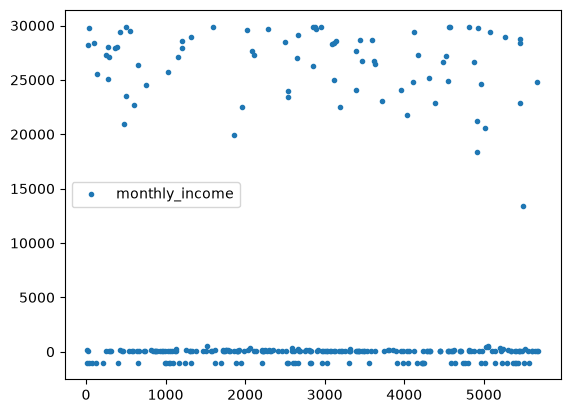

In [403]:
df1[df1["monthly_income"]<30_000].plot(y ="monthly_income", style = ".")
print ( "Строк с ошибкой monthly_income: " ,(df1["monthly_income"] < 5_000).sum() )

Проверили значения monthly_income для каждого из пользователей. Видно, что есть ряд клиентов (233 штук) со значениями <5_000. Очевидно это ошибки записи.

Строк amount < 0:  7434
status
возврат      7434
отклонено       0
успешно         0
Name: count, dtype: int64
(7434, 9)


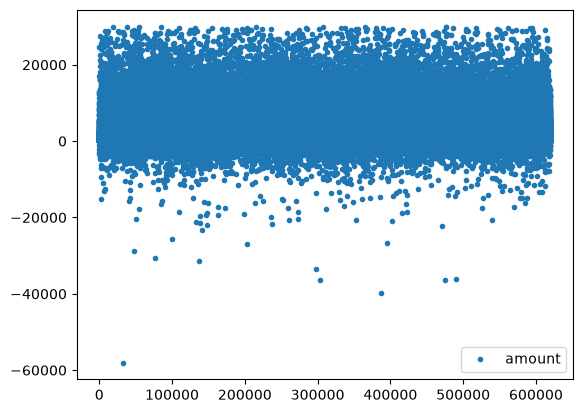

In [404]:
df2[df2["amount"]<30_000].plot(y ="amount", style = ".")
print ( "Строк amount < 0: " ,(df2["amount"] < 0).sum() )

negative = df2["amount"] < 0

print(df2.loc[negative, "status"].value_counts(dropna=False))

print(df2[df2["status"] == "возврат"].shape)

На графике транзакций amount видно что есть достаточно значений меньше нуля, проверка показала, что все эти значения соответствуют статусу возврат и не требуют исправления. Статус возврата всегда обозначается минусом в amount.

In [405]:
bAr = df1["birth_date"] < df1["registration_date"]
bAco = df1["birth_date"] < df1["card_open_date"]
bAll = df1["birth_date"] < df1["app_last_login"]
rAco = df1["registration_date"] <= df1["card_open_date"]
rAll = df1["registration_date"] <= df1["app_last_login"]
# coAll = df1["card_open_date"] <= df1["app_last_login"]

NotNA_bAr = df1["birth_date"].notna() & df1["registration_date"].notna() & ~bAr
NotNA_bAco = df1["birth_date"].notna() & df1["card_open_date"].notna() & ~bAco
NotNA_bAll = df1["birth_date"].notna() & df1["app_last_login"].notna() & ~bAll
NotNA_rAco = df1["registration_date"].notna() & df1["card_open_date"].notna() & ~rAco
NotNA_rAll = df1["registration_date"].notna() & df1["app_last_login"].notna() & ~rAll
# NotNA_coAll = df1["card_open_date"].notna() & df1["app_last_login"].notna() & ~coAll
error_dates = (NotNA_bAr | NotNA_bAco | NotNA_bAll | NotNA_rAco | NotNA_rAll)

print("Строк с нарушениями:", error_dates.sum())


Строк с нарушениями: 13


Проверили соответсвие дат на логический порядок. нужно проверять каждую пару дат, ведь некоторые столбцы могут быть NA. Оставили возможность того, что открытие карты может быть позже последнего захода в приложение. Также наложил запрет на последний загод раньше регистрации в банке: клиент мог бы зайти в приложение раньше регистрации, но у нас не было бы таких данных в таблице.

Всего строк с нарушением порядка: 13 .

### 2.4. Связь между таблицами

Свяжем две таблицы по client_id. 

In [406]:
print("-----Неизвестные клиенты, их транзакции------")
unknown_client = ( df2["client_id"].notna() & ~df2["client_id"].isin(df1["client_id"]))
print( "Кол-во транзакций от неизв. клиентов " ,unknown_client.sum())
print(df2[unknown_client])

print("-----Неизвестные клиенты------")
print("Кол-во неизв. клиентов", df2.loc[unknown_client, "client_id"].nunique())
print("id_client")
print(df2.loc[unknown_client, "client_id"].unique())

-----Неизвестные клиенты, их транзакции------
Кол-во транзакций от неизв. клиентов  29639
        txn_id client_id         txn_datetime    amount currency             category mcc_code channel     status
8       990088   C000376  2023-12-28 16:31:44    736.69      RUB       Онлайн-сервисы     5815   Карта    успешно
10      100002   C001142  2024-01-01 02:33:55    299.47      RUB     Связь и интернет     4814     СБП    успешно
38      100030   C000946  2024-01-01 06:43:37   2494.59      RUB       Одежда и обувь     5651   Токен    успешно
43      100035   C003516  2024-01-01 07:00:25    800.20      RUB             Продукты     5411     СБП    успешно
44      100036   C001491  2024-01-01 07:04:46    831.42      RUB     Кафе и рестораны     5812   Токен    успешно
...        ...       ...                  ...       ...      ...                  ...      ...     ...        ...
526671  629464   C001410  2025-03-31 18:47:04    471.62      RUB               Аптеки     5912   Карта    успешн

Анализ показал, что в базе по транзакциям есть 362 client_id которых нет в базе данных клиентов. Эти клиенты совершили за все охватываемое время 29639 транзакций.

In [407]:
print("-------Клиенты без транзацкий --------")
clients_NOtxn = (df1["client_id"].notna() & ~df1["client_id"].isin(df2["client_id"]))
print(clients_NOtxn.sum())
print(df1[clients_NOtxn])

-------Клиенты без транзацкий --------
12
     client_id birth_date gender                city      segment loyalty_tier    card_type registration_date card_open_date            income_source  \
1156   C000205 1956-08-28      Ж     Санкт Петербург     Массовый      Базовый    Кредитная        2024-11-17     2025-05-13  Зарплата в другом банке   
1184   C000148 1967-08-14      Ж         Новосибирск   Зарплатный      Базовый    Дебетовая        2020-12-10     2025-03-31   Зарплата в нашем банке   
1281   C004130 1992-06-23      М  г. Санкт-Петербург     Массовый      Базовый    Дебетовая        2023-03-29     2025-03-24                Не указан   
2142   C002450 1946-08-28      М     Санкт Петербург     Массовый       Золото    Дебетовая        2019-11-21     2025-03-25  Зарплата в другом банке   
2253   C002639 1971-06-20      Ж              МОСКВА  Премиальный       Золото  Премиальная        2021-02-03     2025-03-31                Не указан   
2837   C002066 1945-06-18      Ж        

Анализ показал, что есть 12 клиентов у которых не совершено ни одной транзакции.

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

## Вывод по таблице clients и transactions:

* 55 дублей по client_id. 40 являются полными дублями , 15 записей с одинаковыми значениями client_id и разными значениями по другим столбцам.
* 1500 дублей по txn_id. 1288 являются полными дублями, 212 записей с одинаковыми значениями txn_id и разными значениями по другим столбцам
* 12 клиентов у которых не совершено ни одной транзакции
* 362 client_id которых нет в бд (29639 транзакций).
* 13строк с нарушением логического порядка дат
* 234 штук клиента со значениями monthly_income < 5_000
* В столбце category таблицы transactions имеются названия с разным форматированием (после FIX стоит проверить соответсвие category и mcc_code)
* В столбце city таблицы clients имеются названия с разным форматированием
* столбец txn_datetime остался str, что говорит о том, что в записях присутствуют строки с несоблюдением формата

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

добавим код для воронки, он нам понадобится позже.

In [408]:
df1FIX = df1.copy()
df2FIX = df2.copy()

funnel = []

def checkpoint(step):
    funnel.append({
        "Этап": step,
        "Клиентов": len(df1FIX),
        "Транзакций": len(df2FIX),
    })

checkpoint("До очистки")

### 3.1.1 Типы, даты, числа

  client_id birth_date gender             city   segment loyalty_tier  card_type registration_date card_open_date income_source  monthly_income  \
0   C001415 1968-12-11      М              СПб  Массовый      Базовый  Дебетовая        2015-02-16     2019-06-10     Не указан            <NA>   
1   C005054 1969-11-01      М  Санкт-Петербург  Массовый      Базовый  Кредитная        2014-01-22     2016-07-27     Не указан           69900   
2   C005780 1958-01-17      М        г. Москва  Массовый      Серебро  Дебетовая        2015-06-30     2017-12-18     Не указан            <NA>   
3   C003736 1983-04-14      М           Казань  Массовый      Базовый  Дебетовая        2017-11-18     2022-01-01     Не указан           67400   
4   C004260 1972-01-05      М      Новосибирск   Private      Платина  Дебетовая        2015-03-02     2020-03-03     Не указан          481900   

  has_mobile_app app_last_login satisfaction_score  branch_code marketing_opt_in  
0            Нет            NaT   

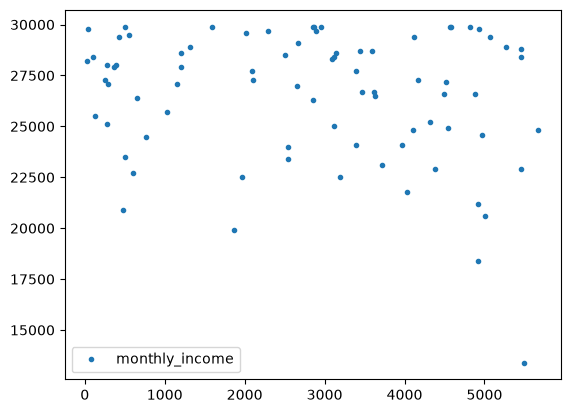

In [409]:

df1FIX.loc[df1FIX["monthly_income"] < 5_000, "monthly_income"] = np.nan
df1FIX[df1FIX["monthly_income"]<30_000].plot(y ="monthly_income", style = ".")
df1FIX["monthly_income"] = df1FIX["monthly_income"].astype("Int64")
print(df1FIX.head())

### 3.1.1 Дубли

* Неполные дубли по клиентам польностью удаляем, как было сказано, нет возможности узнать какой город / сегмент указан верно. Чтобы не оставлять случайным образом из двух записей верную принято решение удалить все дубли (15). 
* В полных дублях по транзакциям и клиентам оставим одну запись. 
* 362 клиента, которых нет в clients, но есть в transactions мы удалим по причине того, что мы для них не сможем разспределить его в какую-либо из групп клиентов.
* 12 клиентов без транзакций удалим, ведь для них мы не можем ввести метрику активности.
* Связанные записи с удаленными клиентами также удалим
* добавим в этот раздел удаление дат с неврным логическим порядком для простоты

In [410]:
mask_df1_dupID = df1FIX["client_id"].duplicated(keep=False)
mask_df1_dupFull = df1FIX.duplicated(keep=False)
mask_df1_extraFull = df1FIX.duplicated(keep="first")
clients_NOtxn = ~df1FIX["client_id"].isin(df2FIX["client_id"])


bAr = df1FIX["birth_date"] < df1FIX["registration_date"]
bAco = df1FIX["birth_date"] < df1FIX["card_open_date"]
bAll = df1FIX["birth_date"] < df1FIX["app_last_login"]
rAco = df1FIX["registration_date"] <= df1FIX["card_open_date"]
rAll = df1FIX["registration_date"] <= df1FIX["app_last_login"]
# coAll = df1["card_open_date"] <= df1["app_last_login"]

NotNA_bAr = df1FIX["birth_date"].notna() & df1FIX["registration_date"].notna() & ~bAr
NotNA_bAco = df1FIX["birth_date"].notna() & df1FIX["card_open_date"].notna() & ~bAco
NotNA_bAll = df1FIX["birth_date"].notna() & df1FIX["app_last_login"].notna() & ~bAll
NotNA_rAco = df1FIX["registration_date"].notna() & df1FIX["card_open_date"].notna() & ~rAco
NotNA_rAll = df1FIX["registration_date"].notna() & df1FIX["app_last_login"].notna() & ~rAll
# NotNA_coAll = df1["card_open_date"].notna() & df1["app_last_login"].notna() & ~coAll
error_dates = (NotNA_bAr | NotNA_bAco | NotNA_bAll | NotNA_rAco | NotNA_rAll)


mask_df1_remove = ((mask_df1_dupID & ~mask_df1_dupFull) | mask_df1_extraFull | clients_NOtxn | error_dates)

print("--------------------------")

mask_df2_dupID = df2FIX["txn_id"].duplicated(keep=False)
mask_df2_dupFull = df2FIX.duplicated(keep=False)
mask_df2oneRogue = mask_df2_dupID & ~mask_df2_dupFull # пометка
mask_df2_extraFull = df2FIX.duplicated(keep="first")
valid_client_ids = df1FIX.loc[~mask_df1_remove, "client_id"]
unknown_client = ~df2FIX["client_id"].isin(valid_client_ids)


mask_df2_remove = (mask_df2_extraFull | unknown_client)

print(df2FIX[mask_df2oneRogue].to_string())

df1FIX = df1FIX.loc[~mask_df1_remove].copy()
df2FIX = df2FIX.loc[~mask_df2_remove].copy()

checkpoint("После общей фильтрации клиентов и транзакций")


print("Удалили ", mask_df1_remove.sum(), " записей клиентов")
print("Удалили ", mask_df2_remove.sum(), " записей транзакций")


--------------------------
        txn_id client_id         txn_datetime    amount currency             category mcc_code      channel     status
1231    101217   C003610           2024-01-02   3085.07      RUB       Одежда и обувь     5651  Онлайн-банк    успешно
1232    101217   C003610  2024-01-02 17:27:12   3085.07      RUB       Одежда и обувь     5651  Онлайн-банк    успешно
1830    101814   C004398           2024-01-03   1132.14      RUB             Продукты     5411        Токен    успешно
1831    101814   C004398  2024-01-03 15:25:54   1132.14      RUB             Продукты     5411        Токен    успешно
2633    102615   C001608           2024-01-04   2189.35      RUB             Продукты     5411        Карта    успешно
2634    102615   C001608  2024-01-04 16:47:19   2189.35      RUB             Продукты     5411        Карта    успешно
8791    108761   C004431           2024-01-10   1081.37      RUB               Аптеки     5912        Карта    успешно
8792    108761   C004

In [411]:
accurate = df2FIX["txn_datetime"].str.contains(":", na=False)
ids_with_time = df2FIX.loc[accurate, "txn_id"]
mask_Naccurate = df2FIX["txn_datetime"].str.len().eq(10) & df2FIX["txn_id"].isin(ids_with_time)
print("Удаляем строк:", mask_Naccurate.sum())
df2FIX = df2FIX.loc[~mask_Naccurate].copy()
checkpoint("После удаления дублей по транзакциям с точным и менее точным форматом")


mask_df2_dupID = df2FIX["txn_id"].duplicated(keep=False)
mask_df2_dupFull = df2FIX.duplicated(keep=False)
mask_df2oneRogue = mask_df2_dupID & ~mask_df2_dupFull # пометка

print(df2FIX[mask_df2oneRogue].to_string())


parsed_dates = pd.to_datetime(df2FIX["txn_datetime"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

wrong_format = (df2FIX["txn_datetime"].notna() & parsed_dates.isna())

print("Строк с неверным форматом:", wrong_format.sum())
print(df2FIX[wrong_format])
print(df2FIX.shape)

Удаляем строк: 198
Empty DataFrame
Columns: [txn_id, client_id, txn_datetime, amount, currency, category, mcc_code, channel, status]
Index: []
Строк с неверным форматом: 46899
        txn_id client_id txn_datetime   amount currency             category mcc_code      channel   status
3       990052   C003352   2023-11-27  1131.33      RUB             Продукты     5411        Карта  успешно
15      100007   C002416   2024-01-01  7921.28      RUB       Одежда и обувь     5651        Карта  успешно
21      100013   C002527   2024-01-01  1468.73      RUB                  АЗС     5541        Токен  успешно
29      100021   C001864   2024-01-01  3027.38      RUB       Одежда и обувь     5651        Карта  успешно
90      100082   C004765   2024-01-01  8051.67      RUB       Одежда и обувь     5651        Карта  успешно
...        ...       ...          ...      ...      ...                  ...      ...          ...      ...
619511  990181   C002470   2025-12-30  1020.41      RUB             

Обнаружили даты с неверным форматом, 46905 штук. Оставим как есть.

### 3.2. Категориальные признаки

In [412]:
CITY_FIX = {
    " москва":"Москва",
    "г. Москва":"Москва",
    "МОСКВА":"Москва",
    "Н. Новгород":"Нижний Новгород",
    "Санкт Петербург":"Санкт-Петербург",
    "г. Санкт-Петербург":"Санкт-Петербург",
    "казань":"Казань",
    "г. Новосибирск":"Новосибирск",
    "СПб":"Санкт-Петербург",
    "ЕКАТЕРИНБУРГ":"Екатеринбург",
    "г.Екатеринбург":"Екатеринбург"
}
df1FIX["city"] = df1FIX["city"].replace(CITY_FIX)
print(df1FIX["city"].value_counts(dropna=False))

city
Москва             1668
Санкт-Петербург     945
Нижний Новгород     892
Екатеринбург        700
Казань              698
Новосибирск         696
Name: count, dtype: Int64


Ошибки форматирования исправлены

In [413]:
CATEGORY_FIX = {
    "Кафе/рестораны":"Кафе и рестораны",
    "кафе и рестораны":"Кафе и рестораны",
    "Связь и интернет":"Связь и Интернет"
}

mask = df2FIX["category"].isin(CATEGORY_FIX.keys())
countC = mask.sum()


df2FIX["category"] = df2FIX["category"].replace(CATEGORY_FIX)
df2FIX["category"] = df2FIX["category"].cat.remove_unused_categories()
print(df2FIX["category"].value_counts(dropna=False))
print("------") 
print("Количество cateory ",df2FIX["category"].nunique())
print("Количество mcc_code ", df2FIX["mcc_code"].nunique())
print("------")
print("Изменено строк с неверным форматированием категорий: ", countC)


category
Продукты               155424
Кафе и рестораны        75526
Одежда и обувь          66063
Транспорт               61996
АЗС                     54092
Связь и Интернет        45929
Развлечения и досуг     44827
Аптеки                  42346
Онлайн-сервисы          40850
Name: count, dtype: int64
------
Количество cateory  9
Количество mcc_code  9
------
Изменено строк с неверным форматированием категорий:  58157


Ошибки форматирования исправлены, теперь число category и mcc_code совпадают. Затронуто 61336 строк. Проверим соответсвие mcc_code и category.

In [414]:
code_category_before = df2FIX.groupby(["category", "mcc_code"]).size()
print(code_category_before.to_string())
before = code_category_before.groupby(level="category").max()
print(before)

category             mcc_code
АЗС                  4111            15
                     4814            21
                     5411            15
                     5541         53951
                     5651            23
                     5812            17
                     5815            14
                     5912            15
                     7832            21
Аптеки               4111            16
                     4814            16
                     5411            12
                     5541            16
                     5651            10
                     5812            15
                     5815            16
                     5912         42225
                     7832            20
Кафе и рестораны     4111            20
                     4814            24
                     5411            26
                     5541            24
                     5651            28
                     5812         75321
          

Видно, что есть одна преобладающая пара category и mcc_code для каждого столбца(строки), которую мы и будем считать правильным соответсвием.
остальные пары ошибочны и требуют замены. так как mcc_code это уникальный код, который дается точке, будем считать его основным признаком, на основе которого будем изменять category

In [415]:
CATEGORY_MCC_CODE = {
    "4111" : "Транспорт",
    "4814" : "Связь и Интернет",
    "5411" : "Продукты", 
    "5541" : "АЗС",
    "5651" : "Одежда и обувь",
    "5812" : "Кафе и рестораны",
    "5815" : "Онлайн-сервисы",
    "5912" : "Аптеки",
    "7832" : "Развлечения и досуг"
}

print(df2FIX["mcc_code"].isna().sum())
df2FIX["category"] = df2FIX["mcc_code"].map(CATEGORY_MCC_CODE)

code_category_after = df2FIX.groupby(["category", "mcc_code"]).size()
print(code_category_after.to_string())
after = code_category_after.groupby(level="category").sum()

print("------Измененных строк в категориях----")
print(after-before)
print("---Всего строк затронуто---")
print((after-before).sum())


0
category             mcc_code
Транспорт            4111         62009
Связь и Интернет     4814         45996
Продукты             5411        155162
АЗС                  5541         54117
Одежда и обувь       5651         66075
Кафе и рестораны     5812         75483
Онлайн-сервисы       5815         40885
Аптеки               5912         42445
Развлечения и досуг  7832         44881
------Измененных строк в категориях----
category
Транспорт              171
Связь и Интернет       201
Продукты               150
АЗС                    166
Одежда и обувь         186
Кафе и рестораны       162
Онлайн-сервисы         162
Аптеки                 220
Развлечения и досуг    186
dtype: int64
---Всего строк затронуто---
1604


Изменили неверные категории всего затронуто строк: 1702.

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

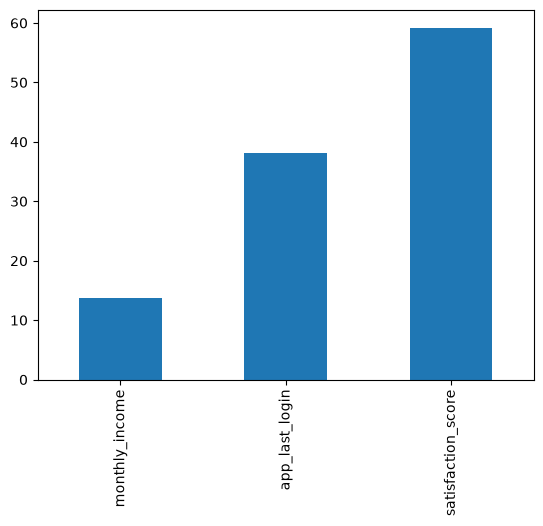

In [416]:
missing = df1FIX.isna().mean()*100
missing = missing[missing>0].plot.bar()

* Видим огромное количество пропусков в колонке app_last_login. Преположение, что эти пропуски связаны с теми людьми, которые не имеют приложения. 
* Механизм пропусков в satisfaction_score очень прост, люди не оставляют отзыв, он не был обязателен, утерянные оценки не найти среди людей, которые просто не оставили балл, поэтому с пропусками ничего не делаем
* monthly_income требует детального рассмотрения с возможностью заполнения пропусков.


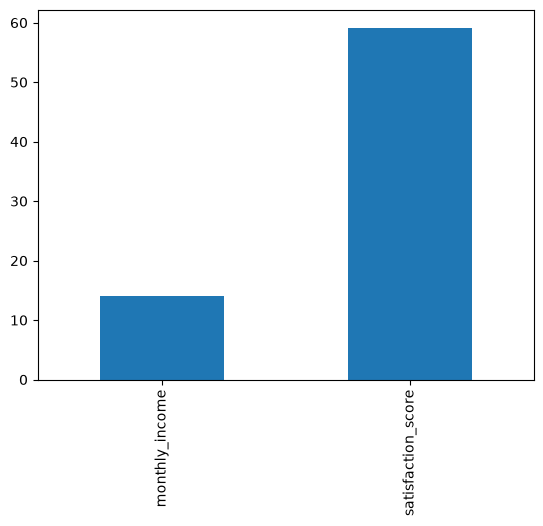

In [417]:
df1VIEW =df1FIX[df1FIX["has_mobile_app"] == "Да"] 
missing = df1VIEW.isna().mean()*100
missing = missing[missing>0].plot.bar()

Предположение подтвердилось, пропуски в app_last_login связаны только лишь с людьми, у которых нет приложения.


<Axes: xlabel='segment'>

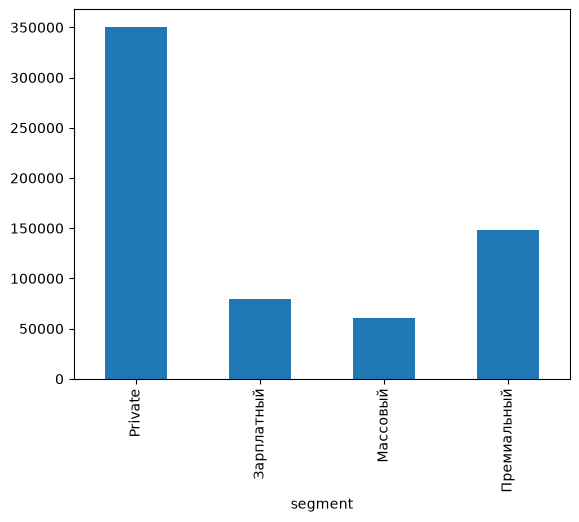

In [418]:
df1FIX.groupby("segment")["monthly_income"].median().plot.bar()

<Axes: xlabel='segment'>

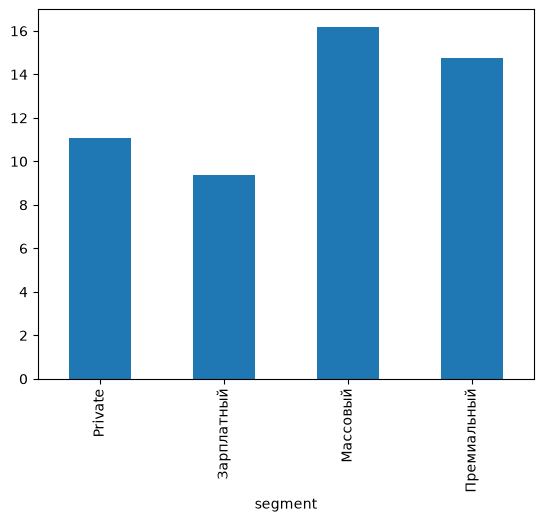

In [419]:
missing = df1FIX["monthly_income"].isna().groupby(df1FIX["segment"], dropna=False).mean() * 100
missing.plot.bar()

Видим, что доля пропусков ни в одном из сегментов не является критической.
предложение: заполнить пропуски медианой по определенным ["city", "segment", "loyalty_tier", "card_type", "gender"]

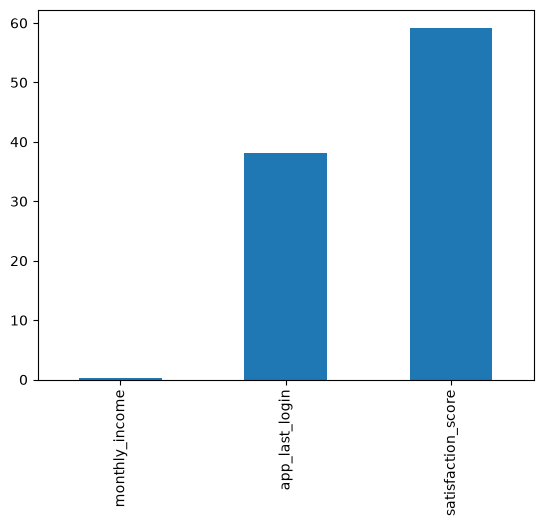

In [420]:
group_median = (
    df1FIX.groupby(
        ["city", "segment", "loyalty_tier", "card_type", "gender"],
        observed=True,
        dropna=False,
    )["monthly_income"]
    .transform("median")
    .round()
    .astype("Int64")
)

df1FIX["monthly_income"] = (
    df1FIX["monthly_income"].fillna(group_median)
)

missing = df1FIX.isna().mean()*100
missing = missing[missing>0].plot.bar()

Заполнили медианой, пропусков нет

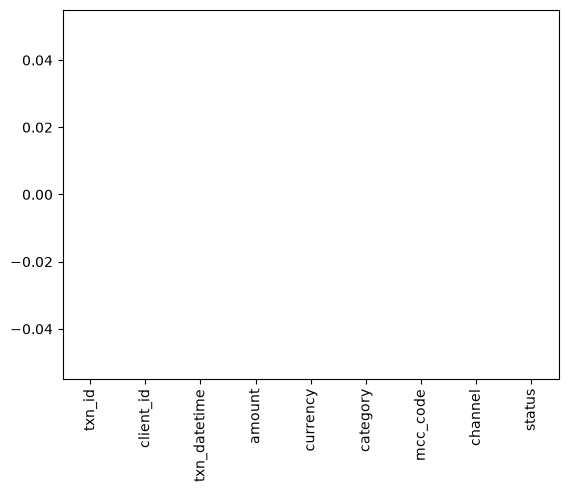

In [421]:
missing = df2FIX.isna().mean()*100
missing = missing.plot.bar()

В таблице Transactions нет пропусков

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

count       5599.0
mean     53.862118
std      14.044254
min           22.0
25%           43.0
50%           52.0
75%           63.0
max           89.0
Name: age, dtype: Float64


<Axes: ylabel='Frequency'>

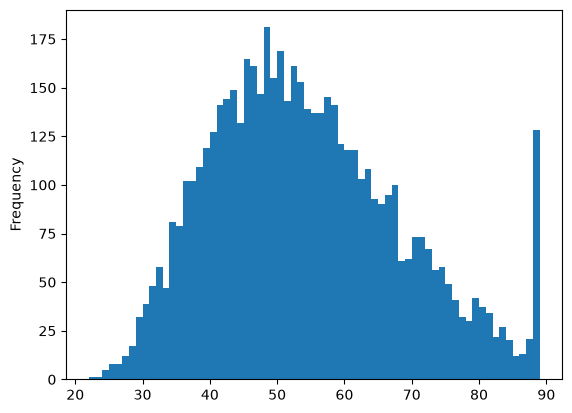

In [422]:
df1FIX["age"] = (2025 - df1FIX["birth_date"].dt.year).astype("Int64")

print(df1FIX["age"].describe())

df1FIX["age"].plot.hist(bins=df1FIX["age"].max()-df1FIX["age"].min())

Видно крупный выброс частоты возраста около 89. Проверим, это ошибка или цензурирование. 

Количество клиентов: 128
has_mobile_app
Нет    98
Да     30
Name: count, dtype: int64
has_mobile_app
Нет    76.5625
Да     23.4375
Name: proportion, dtype: float64


<Axes: title={'center': 'Наличие приложения у клиентов старше 87 лет, процент'}, xlabel='has_mobile_app'>

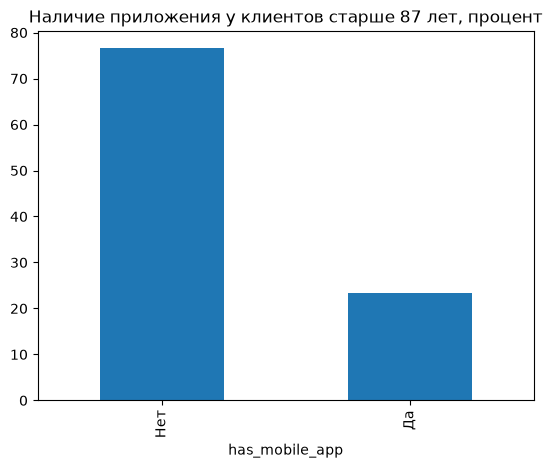

In [423]:
df1VIEW = df1FIX[df1FIX["age"] > 87]

print("Количество клиентов:", len(df1VIEW))
print(df1VIEW["has_mobile_app"].value_counts(dropna=False))

frequency = (df1VIEW["has_mobile_app"].value_counts(normalize=True, dropna=False) * 100)

print(frequency)

frequency.plot.bar(title="Наличие приложения у клиентов старше 87 лет, процент")


<Axes: title={'center': 'Частоты наличия и отсутствия приложения по возрасту'}, xlabel='Возраст, лет', ylabel='Частота, %'>

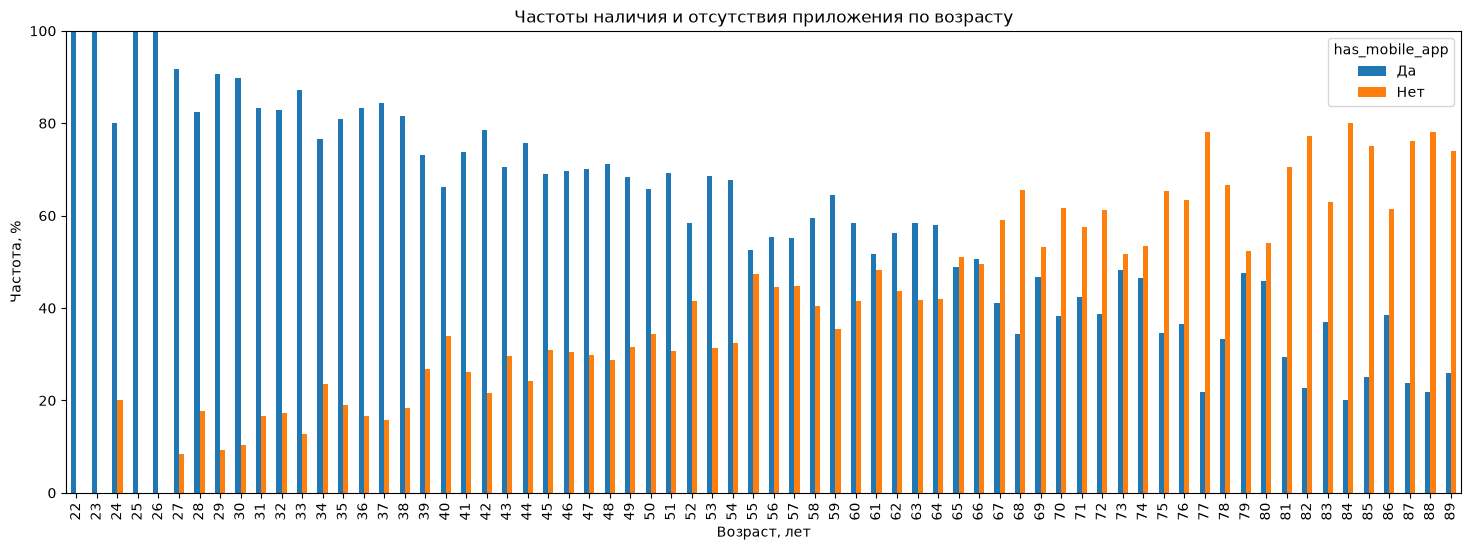

In [424]:
app_by_age = (
    df1FIX.dropna(subset=["age", "has_mobile_app"]).groupby("age", observed=True)["has_mobile_app"].value_counts(normalize=True).unstack(fill_value=0).mul(100).sort_index())

app_by_age.plot.bar(figsize=(18, 6),title="Частоты наличия и отсутствия приложения по возрасту", xlabel="Возраст, лет", ylabel="Частота, %", ylim=(0, 100), rot=90)

Возможно в данных действительно есть как-то лимит на возраст, процент людей использоваших приложение среди схожей группы возраста совпадает. Как минимум можно сказать, что такой выборс не имеет в себе много молодых людей. Оставим его как есть, отметив меткой CAP_AGE

In [425]:
df1FIX["AGE_CAPPED"] = df1FIX["age"].eq(89).fillna(False)

<Axes: title={'center': 'Распределение ежемесячного дохода клиентов'}, xlabel='Ежемесячный доход', ylabel='Количество клиентов'>

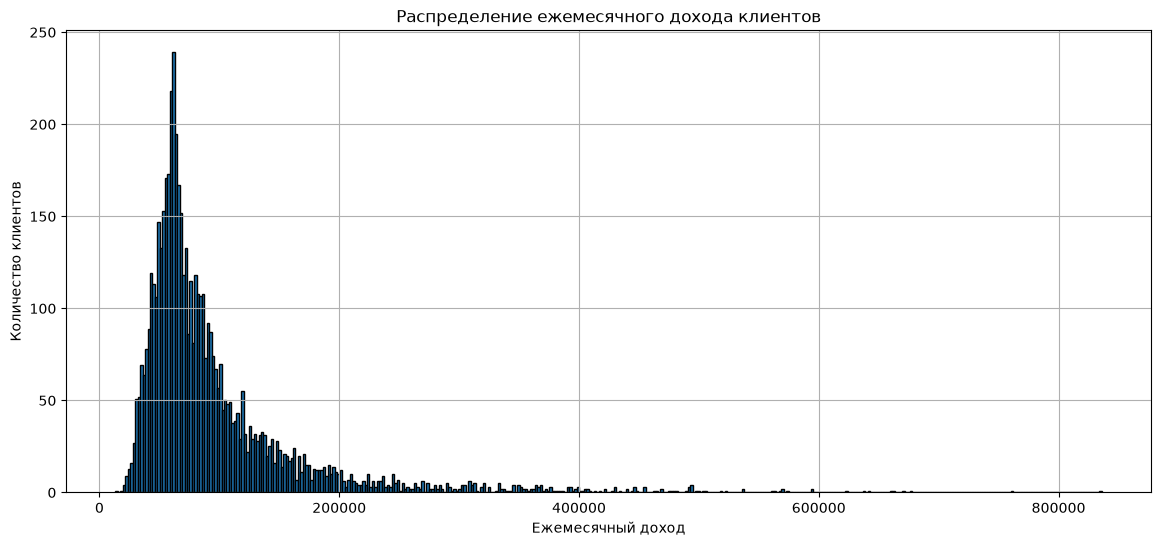

In [426]:
df1FIX[["monthly_income"]].dropna().plot.hist(
    bins=400,
    figsize=(14, 6),
    edgecolor="black",
    title="Распределение ежемесячного дохода клиентов",
    xlabel="Ежемесячный доход",
    ylabel="Количество клиентов",
    legend=False,
    grid=True,
)

пришлось несколько раз изменять заполнение NA для monthly_income, потому как на графике распределения ежемесячного дохода было выдно несколько больших выбросов связанных с запонением пропусков медианой. в окончательной версии видно лишь один крупный выброс

<Axes: >

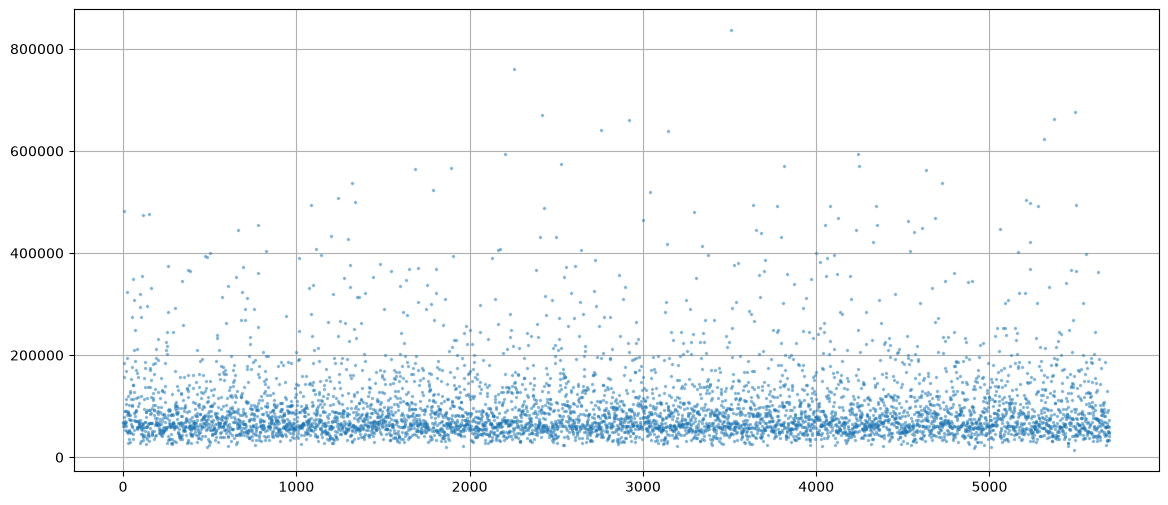

In [427]:
df1FIX.plot(
    y="monthly_income",
    style=".",
    markersize=3,
    alpha=0.4,
    figsize=(14, 6),
    legend=False,
    grid=True,
)

<Axes: >

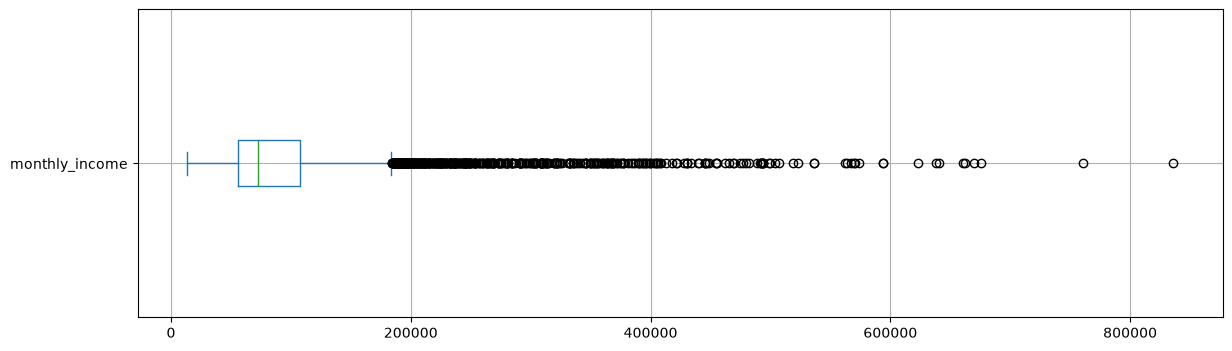

In [428]:
df1FIX[["monthly_income"]].dropna().plot.box(
    vert=False,
    figsize=(14, 4),
    grid=True,
)

<Axes: title={'center': 'Распределение amount: между 1-м и 89-м процентилями'}, xlabel='Сумма', ylabel='Количество записей'>

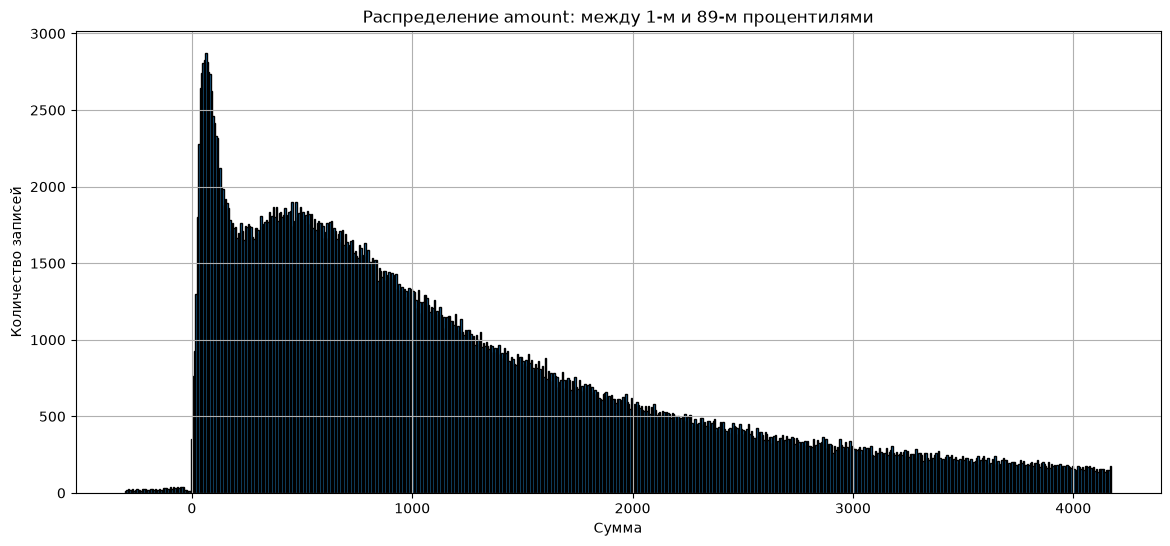

In [429]:
low, high = df2FIX["amount"].quantile([0.01, 0.89])

df2FIX[["amount"]].dropna().plot.hist(
    bins=700,
    range=(low, high),
    figsize=(14, 6),
    edgecolor="black",
    title="Распределение amount: между 1-м и 89-м процентилями",
    xlabel="Сумма",
    ylabel="Количество записей",
    legend=False,
    grid=True,
)

Сам по себе график не показывает явных выбросов по количеству записей, пик в начале вполне может быть статистической закономерностью, в которой лежат например товары первой небходимости (продукты напрмер)

<Axes: title={'center': 'Анализ выбросов суммы транзакций'}, xlabel='Сумма транзакции'>

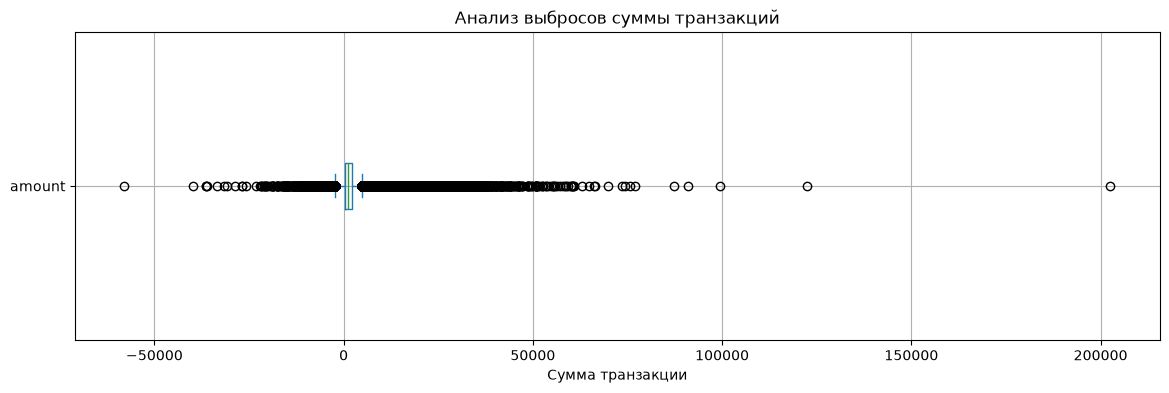

In [430]:
df2FIX[["amount"]].dropna().plot.box(
    vert=False,
    figsize=(14, 4),
    title="Анализ выбросов суммы транзакций",
    xlabel="Сумма транзакции",
    grid=True,
)

Сам факт того, что транзакция выходит за межквартильный размах ещё не говорит о том, что эти строки нужно удалять или изменять. Верхний предел суммы операции ни чем не ограничен и может быть невероятно  большим. Но такие транзакциии стоит проверить, например если крупная транзакция прошла от клиента с низким monthly_income или операция прошла по категории с низким средним чеком (продукты, АЗС)

<Axes: title={'center': 'Суммы отдельных транзакций'}, xlabel='Индекс строки', ylabel='Сумма транзакции'>

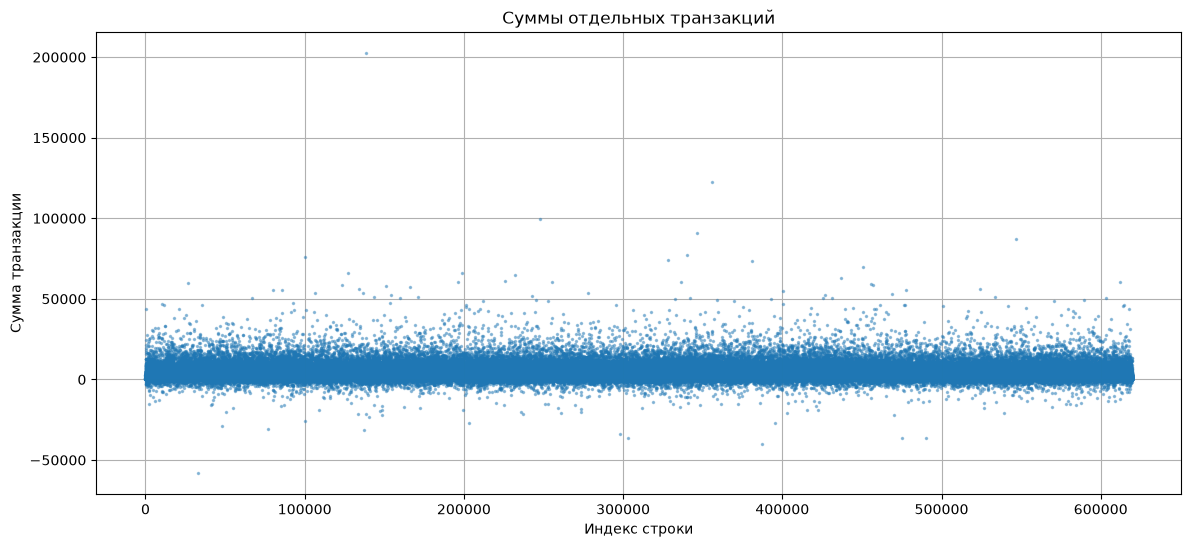

In [431]:
df2FIX.plot(
    y="amount",
    style=".",
    markersize=3,
    alpha=0.4,
    figsize=(14, 6),
    title="Суммы отдельных транзакций",
    xlabel="Индекс строки",
    ylabel="Сумма транзакции",
    legend=False,
    grid=True,
)

На данном этапе оставим для выбросов все, как есть

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [432]:
funnel_df = pd.DataFrame(funnel)

funnel_df["Удалено клиентов"] = (
    -funnel_df["Клиентов"].diff()
).fillna(0).astype(int)

funnel_df["Удалено транзакций"] = (
    -funnel_df["Транзакций"].diff()
).fillna(0).astype(int)

display(funnel_df)

,Этап,Клиентов,Транзакций,Удалено клиентов,Удалено транзакций
0,До очистки,5693,619546,0,0
1,После общей фильтрации клиентов и транзакций,5599,587251,94,32295
2,После удаления дублей по транзакциям с точным ...,5599,587053,0,198


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [433]:
clients_before = df1.copy()

clients_before.loc[
    clients_before["monthly_income"] < 5_000,
    "monthly_income"
] = np.nan

clients_before["monthly_income"] = (
    clients_before["monthly_income"].astype("Int64")
)

client_dup_id = clients_before["client_id"].duplicated(keep=False)
client_dup_full = clients_before.duplicated(keep=False)
client_extra_full = clients_before.duplicated(keep="first")

client_conflict = client_dup_id & ~client_dup_full

client_no_txn = ~clients_before["client_id"].isin(df2["client_id"])

income_original = df1.loc[df1FIX.index, "monthly_income"]

income_needed_fill = (
    income_original.isna()
    | income_original.lt(5_000)
)

n_income_filled = int(
    (income_needed_fill & df1FIX["monthly_income"].notna()).sum()
)

category_original = (
    df2.loc[df2FIX.index, "category"].astype("string")
)

category_normalized = category_original.replace(CATEGORY_FIX)

category_by_mcc = (
    df2FIX["mcc_code"]
    .astype("string")
    .map(CATEGORY_MCC_CODE)
    .astype("string")
)

same_category = (
    category_normalized.eq(category_by_mcc).fillna(False)
    | (category_normalized.isna() & category_by_mcc.isna())
)

n_category_mcc_changed = int((~same_category).sum())

parsed_full = pd.to_datetime(
    df2FIX["txn_datetime"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

n_date_not_full = int(
    (df2FIX["txn_datetime"].notna() & parsed_full.isna()).sum()
)

log_rows = []


def add_log(field, issue, scope, n_rows,
            value_before, action, value_after, rationale):
    log_rows.append({
        "field": field,
        "issue": issue,
        "scope": scope,
        "n_rows": n_rows,
        "value_before": value_before,
        "action": action,
        "value_after": value_after,
        "rationale": rationale,
    })


add_log(
    "monthly_income",
    "Подозрительно низкий ежемесячный доход",
    "clients до удаления строк: monthly_income < 5000",
    int(df1["monthly_income"].lt(5_000).sum()),
    "Значения ниже 5000 рублей",
    "исправлено",
    "Пропуск",
    "Порог 5000 рублей принят как допущение анализа. "
    "Исходный доход не восстанавливается; далее возможно заполнение медианой группы.",
)

add_log(
    "monthly_income",
    "Переход к целочисленному хранению дохода",
    "clients: весь столбец до удаления строк",
    len(df1),
    "float64",
    "исправлено",
    "Int64",
    "Хранение дохода в целых рублях с поддержкой пропусков.",
)

add_log(
    "client_id и остальные поля",
    "Полные дубликаты записей клиентов",
    "clients: duplicated(keep='first') перед общей фильтрацией",
    int(client_extra_full.sum()),
    "Лишние полные копии",
    "удалено",
    "Лишние копии исключены",
    "Предотвратить повторный учёт одинаковых записей клиента.",
)

add_log(
    "client_id",
    "Различающиеся версии записи одного клиента",
    "clients: повтор client_id без полного совпадения строк",
    int(client_conflict.sum()),
    "Одинаковый client_id с различающимися данными",
    "удалено",
    "Строки, соответствующие маске конфликтующих версий, исключены",
    "Не установлено, какие город и сегмент верны. "
    "Случайный выбор версии не используется.",
)

add_log(
    "client_id",
    "Нет операций в исходной таблице транзакций",
    "clients: client_id отсутствует в исходной transactions",
    int(client_no_txn.sum()),
    "Клиенты без зарегистрированных операций",
    "удалено",
    "Исключены из анализируемой выборки",
    "Принято ограничение анализировать клиентов с операциями. "
    "Это ограничение выборки, а не невозможность определить нулевую активность.",
)

add_log(
    "birth_date, registration_date, card_open_date, app_last_login",
    "Нарушение логического порядка дат",
    "clients: error_dates == True перед общей фильтрацией",
    int(error_dates.sum()),
    "Нарушено хотя бы одно из пяти проверяемых условий",
    "удалено",
    "Строки с нарушениями исключены",
    "Принято решение исключить записи с противоречивой хронологией. "
    "Сравнивались только заполненные пары дат.",
)

add_log(
    "txn_id и остальные поля",
    "Полные дубликаты операций",
    "transactions: duplicated(keep='first') перед общей фильтрацией",
    int(df2.duplicated(keep="first").sum()),
    "Лишние полные копии транзакций",
    "удалено",
    "Лишние копии исключены",
    "Предотвратить повторный учёт одной операции.",
)

add_log(
    "client_id",
    "Нет соответствующего клиента в очищенном справочнике",
    "Исходные transactions: client_id отсутствует в df1FIX",
    int((~df2["client_id"].isin(df1FIX["client_id"])).sum()),
    "Операции неизвестных или исключённых клиентов",
    "удалено",
    "Оставлены операции клиентов очищенного справочника",
    "Для анализа операции должны быть связаны с сохраняемой записью клиента.",
)

add_log(
    "txn_datetime",
    "Менее точная версия повторяющейся операции",
    "После общей фильтрации: дата длиной 10 символов "
    "и тот же txn_id присутствует в записи со временем",
    int(mask_Naccurate.sum()),
    "Дата без времени при наличии другой записи того же txn_id",
    "удалено",
    "Менее точная запись исключена",
    "Предпочтение версии со временем. Код проверяет совпадение txn_id "
    "и наличие времени, но не проверяет совпадение остальных полей пары.",
)

add_log(
    "txn_datetime",
    "Дата не разбирается в полном формате даты и времени",
    "Сохраняемые transactions: непустая дата и ошибка разбора "
    "по формату %Y-%m-%d %H:%M:%S",
    n_date_not_full,
    "В том числе даты без времени",
    "оставлено",
    "Исходные значения сохранены",
    "Отсутствие времени само по себе не доказывает ошибку операции. "
    "Перед расчётом активности нужен отдельный разбор дат.",
)

add_log(
    "city",
    "Разные написания одного города",
    "Сохраняемые clients: исходный city входит в ключи CITY_FIX",
    int(
        df1.loc[df1FIX.index, "city"]
        .isin(CITY_FIX.keys())
        .sum()
    ),
    "Например: СПб, Санкт Петербург, г. Санкт-Петербург",
    "исправлено",
    "Единые названия по CITY_FIX",
    "Объединить варианты написания одного города без изменения смысла.",
)

add_log(
    "category",
    "Разные написания одной категории",
    "transactions на этапе нормализации: category входит в CATEGORY_FIX",
    int(countC),
    "Кафе/рестораны; кафе и рестораны; Связь и интернет",
    "исправлено",
    "Кафе и рестораны; Связь и Интернет",
    "Объединить одинаковые категории независимо от написания.",
)

add_log(
    "category",
    "Неиспользуемые уровни категориального типа",
    "Столбец category на этапе remove_unused_categories",
    0,
    "Сохранившиеся в метаданных неиспользуемые категории",
    "исправлено",
    "Неиспользуемые уровни удалены",
    "Изменены метаданные категорий; значения ячеек не изменены.",
)

add_log(
    "category",
    "Категория отличается от категории по принятому справочнику MCC",
    "Сохраняемые transactions: нормализованная категория "
    "не совпадает с CATEGORY_MCC_CODE",
    n_category_mcc_changed,
    "Категория после нормализации названий",
    "исправлено",
    "Категория, определённая по mcc_code",
    "MCC принят за опорный признак. "
    "Это допущение обработки, а не независимое подтверждение каждой операции.",
)

add_log(
    "app_last_login",
    "Отсутствует дата последнего входа",
    "Сохраняемые clients: app_last_login.isna()",
    int(df1FIX["app_last_login"].isna().sum()),
    "NaT",
    "оставлено",
    "NaT",
    "Неизвестная дата не подменяется выдуманной. "
    "Отсутствие приложения рассматривается как возможное объяснение пропуска.",
)

add_log(
    "satisfaction_score",
    "Отсутствует оценка удовлетворённости",
    "Сохраняемые clients: satisfaction_score.isna()",
    int(df1FIX["satisfaction_score"].isna().sum()),
    "Пропуск",
    "оставлено",
    "Пропуск",
    "Предположение: клиент не участвовал в опросе. "
    "Пропуск не приравнивается к нулевой или типичной оценке.",
)

add_log(
    "monthly_income",
    "Отсутствующий доход, включая значения, заменённые на пропуски",
    "Сохраняемые clients: пропуск до заполнения и известная медиана группы",
    n_income_filled,
    "Пропуск",
    "заполнено",
    "Округлённая медиана по city, segment, loyalty_tier, card_type, gender",
    "Использован типичный известный доход клиентов с той же комбинацией "
    "пяти признаков. Известные доходы не изменены. "
    "При отсутствии известных доходов в группе пропуск сохраняется.",
)

add_log(
    "age",
    "Добавление приблизительного возраста",
    "Все сохраняемые клиенты",
    len(df1FIX),
    "Столбец отсутствовал",
    "добавлено",
    "2025 - год рождения",
    "Производный признак для возрастных разрезов. "
    "День и месяц рождения в этом расчёте не учитываются.",
)

add_log(
    "AGE_CAPPED",
    "Концентрация наблюдений на возрасте 89 лет",
    "Все сохраняемые клиенты; True при age == 89",
    len(df1FIX),
    "Столбец отсутствовал",
    "добавлено",
    f"True у {int(df1FIX['AGE_CAPPED'].sum())} клиентов; "
    "False у остальных, включая неизвестный возраст",
    "Метка для дополнительной проверки. Ограничение возраста сверху "
    "не подтверждено. Исходный возраст и дата рождения не заменяются.",
)

add_log(
    "amount",
    "Крайние значения на графиках распределения сумм",
    "Все сохраняемые транзакции",
    len(df2FIX),
    "Исходные суммы, включая крупные и отрицательные",
    "оставлено",
    "Суммы не изменены",
    "Выполнен визуальный анализ. Без подтверждения ошибки "
    "крайние суммы не удаляются и не заменяются.",
)

cleaning_log = pd.DataFrame(log_rows)
cleaning_log["n_rows"] = cleaning_log["n_rows"].astype("Int64")

display(cleaning_log)

cleaning_log.to_csv(
    "../data/interim/cleaning_log.csv",
    index=False,
    encoding="utf-8",
)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,monthly_income,Подозрительно низкий ежемесячный доход,clients до удаления строк: monthly_income < 5000,233,Значения ниже 5000 рублей,исправлено,Пропуск,Порог 5000 рублей принят как допущение анализа...
1,monthly_income,Переход к целочисленному хранению дохода,clients: весь столбец до удаления строк,5693,float64,исправлено,Int64,Хранение дохода в целых рублях с поддержкой пр...
2,client_id и остальные поля,Полные дубликаты записей клиентов,clients: duplicated(keep='first') перед общей ...,40,Лишние полные копии,удалено,Лишние копии исключены,Предотвратить повторный учёт одинаковых записе...
3,client_id,Различающиеся версии записи одного клиента,clients: повтор client_id без полного совпаден...,30,Одинаковый client_id с различающимися данными,удалено,"Строки, соответствующие маске конфликтующих ве...","Не установлено, какие город и сегмент верны. С..."
4,client_id,Нет операций в исходной таблице транзакций,clients: client_id отсутствует в исходной tran...,12,Клиенты без зарегистрированных операций,удалено,Исключены из анализируемой выборки,Принято ограничение анализировать клиентов с о...
5,"birth_date, registration_date, card_open_date,...",Нарушение логического порядка дат,clients: error_dates == True перед общей фильт...,13,Нарушено хотя бы одно из пяти проверяемых условий,удалено,Строки с нарушениями исключены,Принято решение исключить записи с противоречи...
6,txn_id и остальные поля,Полные дубликаты операций,transactions: duplicated(keep='first') перед о...,1288,Лишние полные копии транзакций,удалено,Лишние копии исключены,Предотвратить повторный учёт одной операции.
7,client_id,Нет соответствующего клиента в очищенном справ...,Исходные transactions: client_id отсутствует в...,31069,Операции неизвестных или исключённых клиентов,удалено,Оставлены операции клиентов очищенного справоч...,Для анализа операции должны быть связаны с сох...
8,txn_datetime,Менее точная версия повторяющейся операции,После общей фильтрации: дата длиной 10 символо...,198,Дата без времени при наличии другой записи тог...,удалено,Менее точная запись исключена,Предпочтение версии со временем. Код проверяет...
9,txn_datetime,Дата не разбирается в полном формате даты и вр...,Сохраняемые transactions: непустая дата и ошиб...,46899,В том числе даты без времени,оставлено,Исходные значения сохранены,Отсутствие времени само по себе не доказывает ...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

<Axes: title={'center': 'Распределение приблизительного возраста клиентов'}, xlabel='Возраст, лет', ylabel='Количество клиентов'>

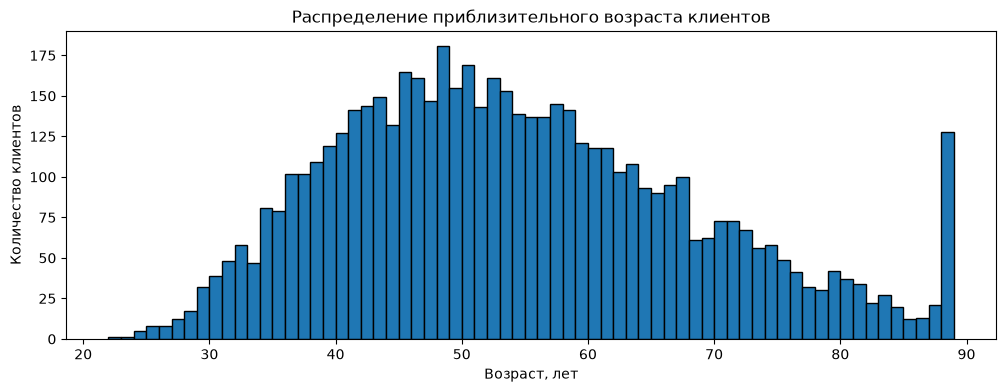

### 5.2. Частотные характеристики категориальных признаков


Признак: gender


,Количество клиентов,"Доля клиентов, %"
gender,,
М,2874,51.33
Ж,2725,48.67



Признак: city


,Количество клиентов,"Доля клиентов, %"
city,,
Москва,1668,29.79
Санкт-Петербург,945,16.88
Нижний Новгород,892,15.93
Екатеринбург,700,12.5
Казань,698,12.47
Новосибирск,696,12.43



Признак: segment


,Количество клиентов,"Доля клиентов, %"
segment,,
Массовый,2848,50.87
Зарплатный,1647,29.42
Премиальный,896,16.00
Private,208,3.71


... (8 outputs left out)


Признак: satisfaction_score


,Количество клиентов,"Доля клиентов, %"
satisfaction_score,,
NaN,3316,59.22
5,640,11.43
3,465,8.31
4,455,8.13
2,442,7.89
1,281,5.02



Признак: marketing_opt_in


,Количество клиентов,"Доля клиентов, %"
marketing_opt_in,,
Да,4906,87.62
Нет,693,12.38


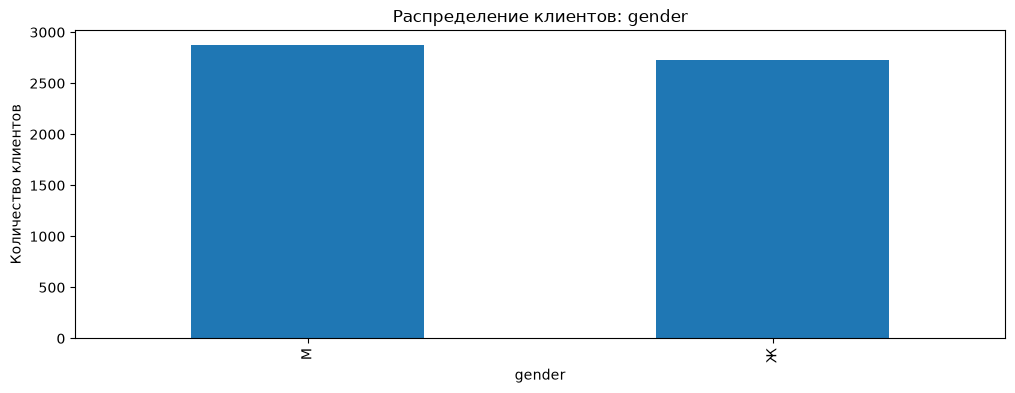

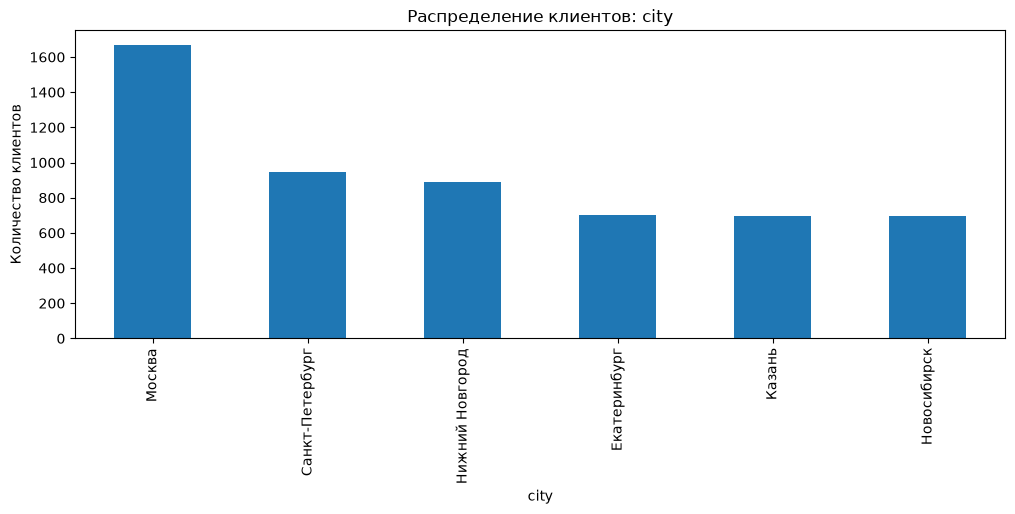

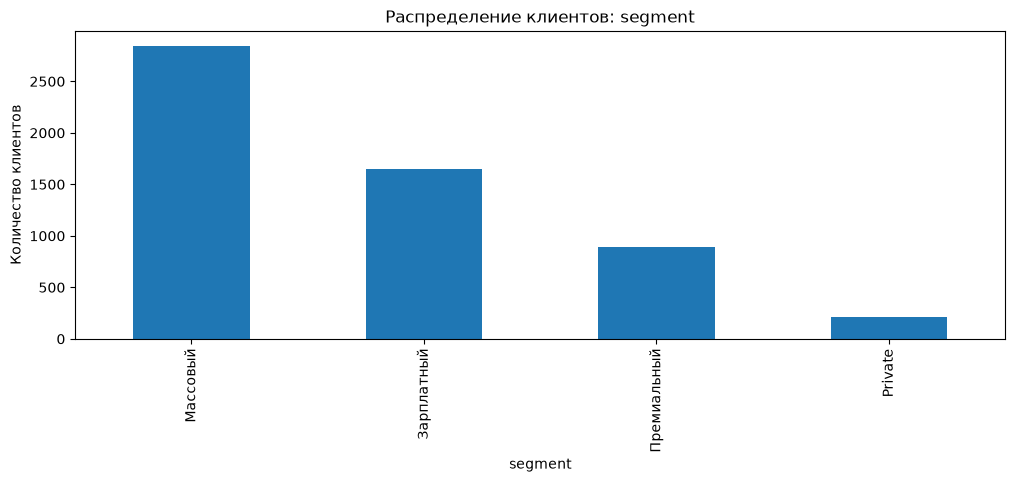

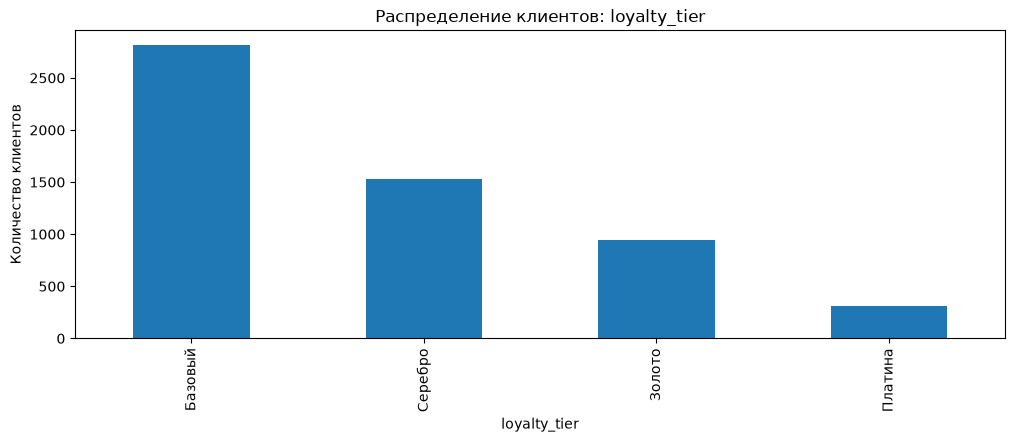

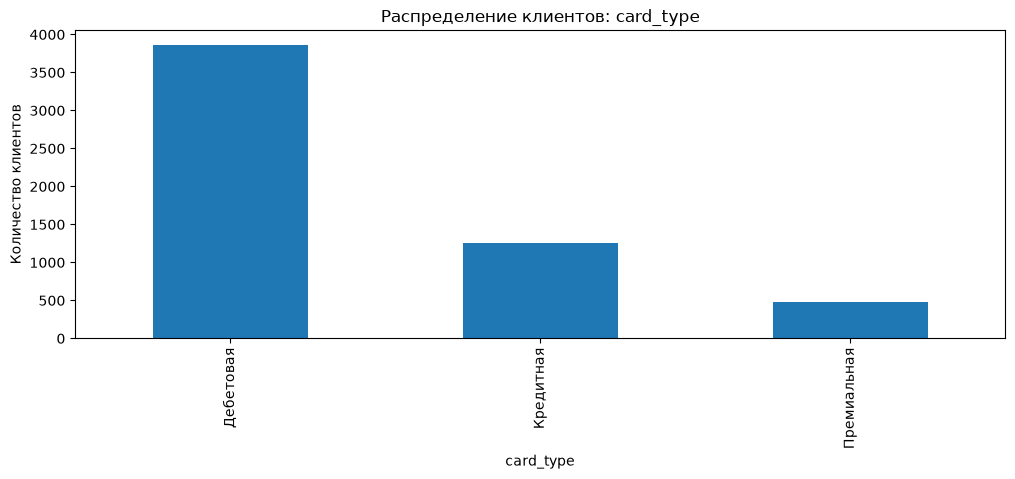

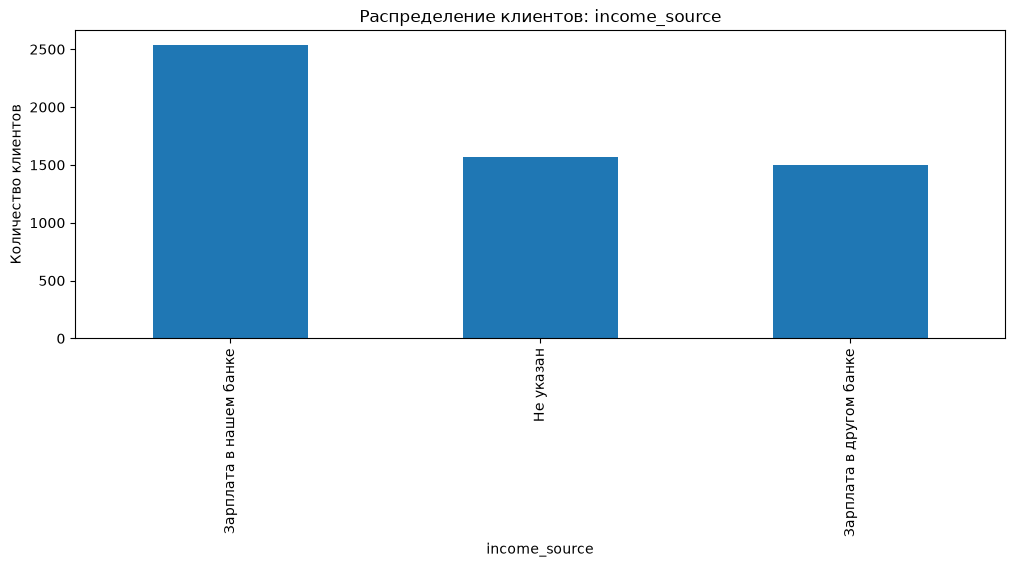

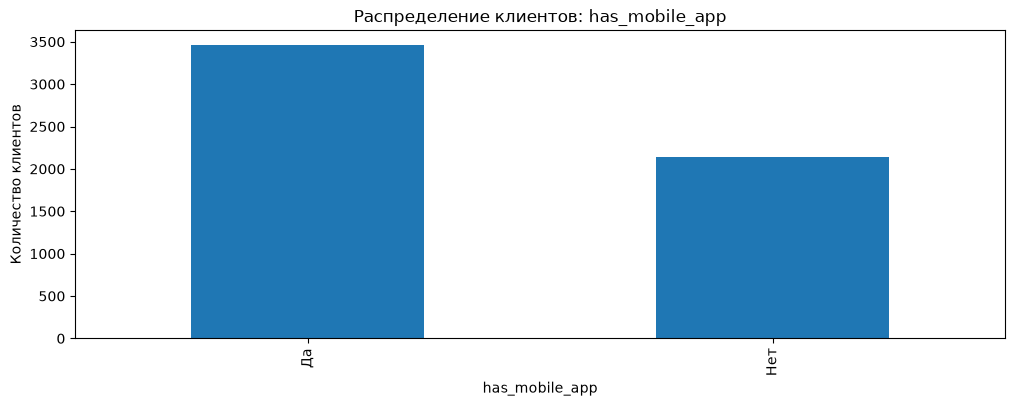

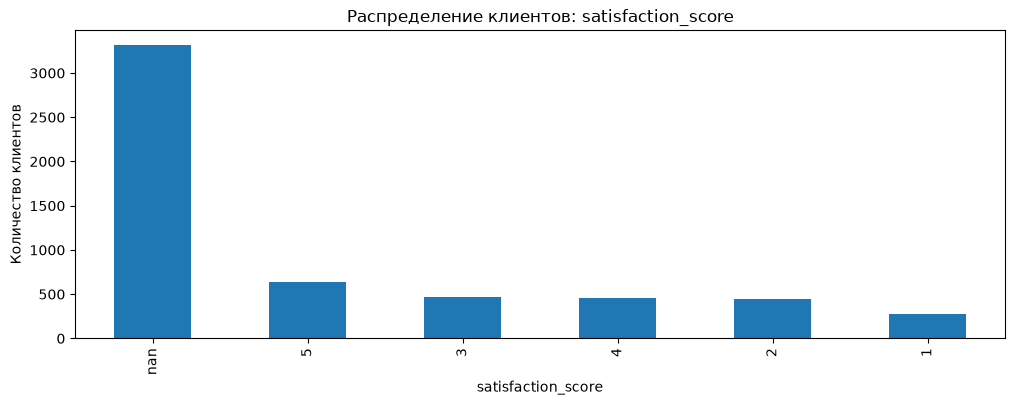

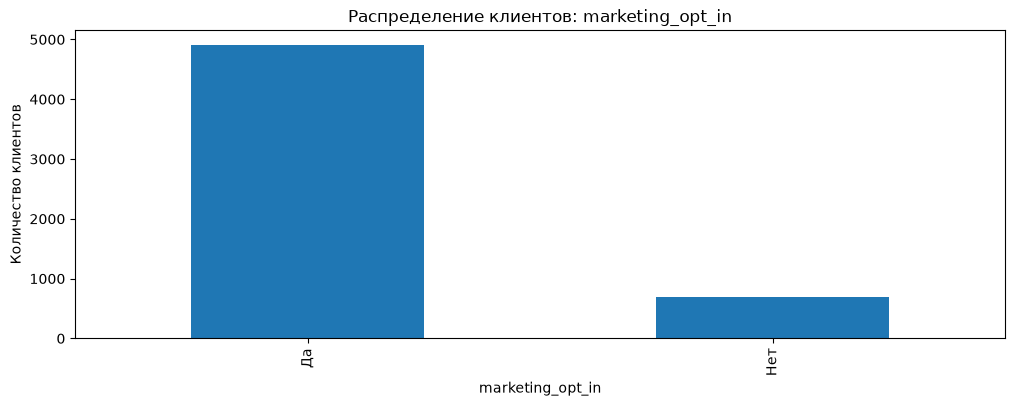

In [439]:
client_categories = [
    "gender",
    "city",
    "segment",
    "loyalty_tier",
    "card_type",
    "income_source",
    "has_mobile_app",
    "satisfaction_score",
    "marketing_opt_in",
]

for column in client_categories:
    frequency = pd.DataFrame({
        "Количество клиентов": (
            df1FIX[column].value_counts(dropna=False)
        ),
        "Доля клиентов, %": (
            df1FIX[column]
            .value_counts(normalize=True, dropna=False)
            .mul(100)
            .round(2)
        ),
    })

    print(f"\nПризнак: {column}")
    display(frequency)

    frequency[["Количество клиентов"]].plot.bar(
        figsize=(12, 4),
        title=f"Распределение клиентов: {column}",
        xlabel=column,
        ylabel="Количество клиентов",
        legend=False,
        rot=90,
    )

### 5.3. Динамика по месяцам

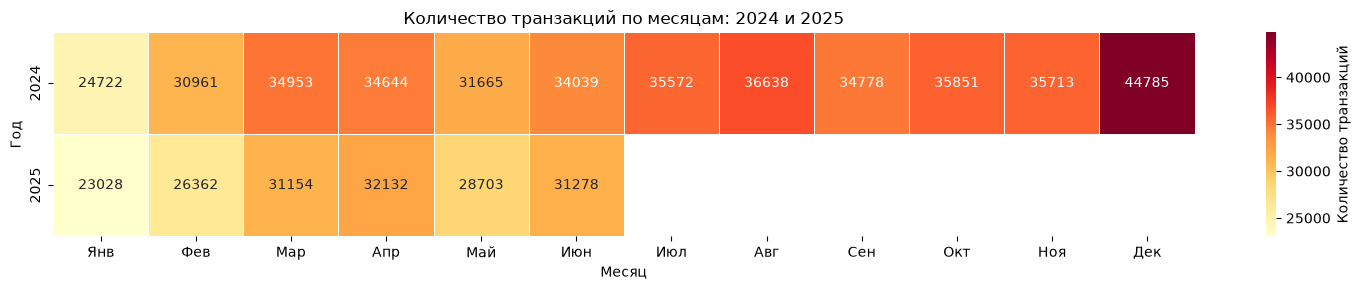

In [443]:
heatmap_data = comparison.T
heatmap_data.index = ["2024", "2025"]
heatmap_data.columns = [
    "Янв", "Фев", "Мар", "Апр", "Май", "Июн",
    "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек",
]

plt.figure(figsize=(15, 3))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    mask=heatmap_data.isna(),
    cbar_kws={"label": "Количество транзакций"},
)

plt.title("Количество транзакций по месяцам: 2024 и 2025")
plt.xlabel("Месяц")
plt.ylabel("Год")
plt.tight_layout()
plt.show()

### 5.4. Разрезы и связи между признаками

In [ ]:
df1FIX.groupby("segment")["monthly_income"].median().plot.bar()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

In [ ]:
txn_activity = txn.loc[
    txn["date"].ge("2024-01-01")
    & txn["date"].lt("2025-07-01")
    & txn["status"].eq("успешно")
    & txn["currency"].eq("RUB")
    & txn["amount"].gt(0)
].copy()

txn_activity["month"] = txn_activity["date"].dt.to_period("M")

In [445]:
months = pd.period_range("2024-01", "2025-06", freq="M")

client_month_index = pd.MultiIndex.from_product(
    [
        df1FIX["client_id"].dropna().unique(),
        months,
    ],
    names=["client_id", "month"],
)

activity_monthly = (
    txn_activity
    .groupby(["client_id", "month"], observed=True)
    .agg(
        n_operations=("txn_id", "size"),
        total_amount=("amount", "sum"),
    )
    .reindex(client_month_index, fill_value=0)
    .reset_index()
)

In [446]:
base_active = activity_monthly.loc[
    activity_monthly["month"].dt.year.eq(2024)
    & activity_monthly["n_operations"].gt(0)
]

n_ref = base_active["n_operations"].median()
s_ref = base_active["total_amount"].median()

if pd.isna(n_ref) or pd.isna(s_ref) or n_ref <= 0 or s_ref <= 0:
    raise ValueError("Недостаточно базовых операций для нормализации")

activity_monthly["n_normalized"] = (
    activity_monthly["n_operations"] / n_ref
)

activity_monthly["amount_normalized"] = (
    activity_monthly["total_amount"] / s_ref
)

activity_monthly["activity"] = (
    0.5 * activity_monthly["n_normalized"]
    + 0.5 * activity_monthly["amount_normalized"]
)

print("Базовая медиана количества операций:", n_ref)
print("Базовая медиана месячной суммы:", s_ref)

display(activity_monthly.head(20))

Базовая медиана количества операций: 6.0
Базовая медиана месячной суммы: 9727.310000000001


,client_id,month,n_operations,total_amount,n_normalized,amount_normalized,activity
0,C001415,2024-01,4,4728.27,0.666667,0.486082,0.576374
1,C001415,2024-02,5,7728.22,0.833333,0.794487,0.81391
2,C001415,2024-03,1,1053.37,0.166667,0.108290,0.137478
3,C001415,2024-04,5,3611.10,0.833333,0.371233,0.602283
4,C001415,2024-05,6,4303.50,1.0,0.442414,0.721207
5,C001415,2024-06,4,2755.32,0.666667,0.283256,0.474961
6,C001415,2024-07,3,2299.03,0.5,0.236348,0.368174
7,C001415,2024-08,4,15529.42,0.666667,1.596476,1.131571
8,C001415,2024-09,5,7609.35,0.833333,0.782267,0.8078
9,C001415,2024-10,2,1080.55,0.333333,0.111084,0.222209


In [450]:
activity_monthly["year"] = activity_monthly["month"].dt.year

activity_comparison = (
    activity_monthly
    .groupby(["client_id", "year"])["activity"]
    .mean()
    .unstack("year")
    .reindex(columns=[2024, 2025])
    .rename(columns={
        2024: "activity_2024",
        2025: "activity_2025",
    })
)

activity_comparison["change"] = (
    activity_comparison["activity_2025"]
    - activity_comparison["activity_2024"]
)

activity_comparison["change_pct"] = (
    activity_comparison["change"]
    .div(
        activity_comparison["activity_2024"].where(
            activity_comparison["activity_2024"].gt(0)
        )
    )
    .mul(100)
)

display(activity_comparison.head(40))

year,activity_2024,activity_2025,change,change_pct
client_id,,,,
C000001,0.722449,0.46944,-0.253009,-35.020982
C000002,0.750516,0.250443,-0.500072,-66.63048
C000003,0.658911,0.160328,-0.498582,-75.667684
C000004,1.20259,0.941848,-0.260742,-21.681701
C000005,1.954883,1.488773,-0.466111,-23.843398
C000006,0.0,0.015841,0.015841,<NA>
C000007,2.451009,0.626955,-1.824053,-74.420526
C000008,2.7402,2.301896,-0.438304,-15.99532
C000009,0.14168,0.363922,0.222243,156.862899


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")